<a href="https://colab.research.google.com/github/Praseedas/example-repo/blob/main/NGS_Genomic_Data_Processing_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import os

BASE = "/content/NGS_Pipeline"

folders = [
    "data/raw",
    "data/processed",
    "reference",
    "qc/raw",
    "qc/trimmed",
    "alignment",
    "variants/raw",
    "variants/filtered",
    "logs",
    "scripts",
    "reports"
]

for folder in folders:
    os.makedirs(os.path.join(BASE, folder), exist_ok=True)

print("Project directory created successfully!")

!ls -R /content/NGS_Pipeline


Project directory created successfully!
/content/NGS_Pipeline:
alignment  data  logs  qc  reference  reports  scripts	variants

/content/NGS_Pipeline/alignment:

/content/NGS_Pipeline/data:
processed  raw

/content/NGS_Pipeline/data/processed:

/content/NGS_Pipeline/data/raw:

/content/NGS_Pipeline/logs:

/content/NGS_Pipeline/qc:
raw  trimmed

/content/NGS_Pipeline/qc/raw:

/content/NGS_Pipeline/qc/trimmed:

/content/NGS_Pipeline/reference:

/content/NGS_Pipeline/reports:

/content/NGS_Pipeline/scripts:

/content/NGS_Pipeline/variants:
filtered  raw

/content/NGS_Pipeline/variants/filtered:

/content/NGS_Pipeline/variants/raw:


In [2]:

!apt-get update -qq

!apt-get install -y \
    fastqc \
    fastp \
    bwa \
    samtools \
    bcftools \
    freebayes \
    tabix \
    time


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Package freebayes is not available, but is referred to by another package.
This may mean that the package is missing, has been obsoleted, or
is only available from another source

E: Package 'freebayes' has no installation candidate


In [3]:

!mkdir -p /content/bin

!curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xvj -C /content bin/micromamba

!/content/bin/micromamba --version


bin/micromamba
2.10.0


In [4]:

%env MAMBA_ROOT_PREFIX=/content/micromamba

!/content/bin/micromamba install -y -c conda-forge -c bioconda freebayes


env: MAMBA_ROOT_PREFIX=/content/micromamba
[+] 0.0s
Fetch Shard Index for conda-forge/linux-64                                                ✔ Done (0.1 sec)
Fetch Shard Index for conda-forge/noarch                                                  ✔ Done (0.1 sec)
Fetching and Parsing Packages' Shards                                                     ✔ Done (0.0 sec)
Using Flat Repodata for conda-forge/linux-64                                             ✔ Done (23.6 sec)
Using Cached Shard Index for conda-forge/noarch                                                     ✔ Done
Using Cached Shard Index for conda-forge/linux-64                                                   ✔ Done
Fetching and Parsing Packages' Shards                                                     ✔ Done (0.0 sec)
Using Flat Repodata for conda-forge/noarch                                                ✔ Done (8.5 sec)
Fetch Shard Index for bioconda/linux-64                                                   ✔ 

In [5]:

!/content/micromamba run -n base freebayes --version


/bin/bash: line 1: /content/micromamba: Is a directory


In [6]:
!ls -l /content/bin/micromamba
!ls -l /content/micromamba

-rwxrwxr-x 1 root root 19028608 Oct 26 14:29 /content/bin/micromamba
total 60
drwxr-xr-x  2 root root 12288 Nov 11 04:17 bin
drwxr-xr-x  2 root root  4096 Nov 11 04:17 conda-meta
drwxr-xr-x  3 root root  4096 Nov 11 04:17 etc
drwxr-xr-x 18 root root  4096 Nov 11 04:17 include
drwxr-xr-x 18 root root 12288 Nov 11 04:17 lib
drwxr-xr-x  3 root root  4096 Nov 11 04:17 libexec
drwxr-xr-x  4 root root  4096 Nov 11 04:17 pkgs
drwxr-xr-x  2 root root  4096 Nov 11 04:17 sbin
drwxr-xr-x 17 root root  4096 Nov 11 04:17 share
drwxr-xr-x  4 root root  4096 Nov 11 04:17 ssl
drwxr-xr-x  3 root root  4096 Nov 11 04:17 x86_64-conda-linux-gnu


In [7]:
!/content/bin/micromamba --version

2.10.0


In [8]:
!/content/bin/micromamba run -n base freebayes --version

version:  v1.3.10


In [9]:
import os

!ls -lh /content/NGS_Pipeline/data/raw/
!ls -lh /content/NGS_Pipeline/reference/

total 0
total 0


In [10]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [11]:

import os

DRIVE_DIR = "/content/drive/MyDrive/Genomic_Data_Analyst_Assignment/Task_2_Pipeline"

os.makedirs(DRIVE_DIR, exist_ok=True)

print("Google Drive folder created:", DRIVE_DIR)


Google Drive folder created: /content/drive/MyDrive/Genomic_Data_Analyst_Assignment/Task_2_Pipeline


In [13]:

%%bash

mkdir -p /content/NGS_Pipeline/data/raw
mkdir -p /content/NGS_Pipeline/reference

cd /content/NGS_Pipeline/data/raw

wget -c https://zenodo.org/records/3243160/files/proband_R1.fq.gz
wget -c https://zenodo.org/records/3243160/files/proband_R2.fq.gz

cd /content/NGS_Pipeline/reference

wget -c https://zenodo.org/records/3243160/files/hg19_chr8.fa.gz


--2026-11-11 04:25:56--  https://zenodo.org/records/3243160/files/proband_R1.fq.gz
Resolving zenodo.org (zenodo.org)... 188.185.47.192, 137.138.121.78, 188.185.40.132, ...
Connecting to zenodo.org (zenodo.org)|188.185.47.192|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 174028289 (166M) [application/octet-stream]
Saving to: ‘proband_R1.fq.gz’

     0K .......... .......... .......... .......... ..........  0%  221K 12m47s
    50K .......... .......... .......... .......... ..........  0%  513K 9m9s
   100K .......... .......... .......... .......... ..........  0%  208M 6m6s
   150K .......... .......... .......... .......... ..........  0%  509K 5m58s
   200K .......... .......... .......... .......... ..........  0% 12.0M 4m49s
   250K .......... .......... .......... .......... ..........  0%  536K 4m54s
   300K .......... .......... .......... .......... ..........  0%  151M 4m12s
   350K .......... .......... .......... .......... ..........  0%  220M 3

In [14]:

import os

folders = [
    "/content/NGS_Pipeline/data/raw",
    "/content/NGS_Pipeline/reference"
]

for folder in folders:
    print("\nFolder:", folder)

    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)

        print(
            filename,
            " | Size:",
            round(os.path.getsize(filepath) / (1024**2), 2),
            "MB"
        )



Folder: /content/NGS_Pipeline/data/raw
proband_R2.fq.gz  | Size: 165.44 MB
proband_R1.fq.gz  | Size: 165.97 MB

Folder: /content/NGS_Pipeline/reference
hg19_chr8.fa.gz  | Size: 44.72 MB


In [15]:

import os
import gzip

raw_dir = "/content/NGS_Pipeline/data/raw"
ref_dir = "/content/NGS_Pipeline/reference"

files = [
    os.path.join(raw_dir, "proband_R1.fq.gz"),
    os.path.join(raw_dir, "proband_R2.fq.gz"),
    os.path.join(ref_dir, "hg19_chr8.fa.gz")
]

for filepath in files:
    print("\nChecking:", os.path.basename(filepath))

    if not os.path.exists(filepath):
        print("ERROR: File not found")
        continue

    size = os.path.getsize(filepath) / (1024**2)
    print("File size:", round(size, 2), "MB")

    try:
        with gzip.open(filepath, "rb") as f:
            f.read(1024)
        print("GZIP integrity: PASS")
    except Exception as e:
        print("GZIP integrity: FAIL", e)



Checking: proband_R1.fq.gz
File size: 165.97 MB
GZIP integrity: PASS

Checking: proband_R2.fq.gz
File size: 165.44 MB
GZIP integrity: PASS

Checking: hg19_chr8.fa.gz
File size: 44.72 MB
GZIP integrity: PASS


In [16]:

%%bash

gzip -t /content/NGS_Pipeline/data/raw/proband_R1.fq.gz
gzip -t /content/NGS_Pipeline/data/raw/proband_R2.fq.gz
gzip -t /content/NGS_Pipeline/reference/hg19_chr8.fa.gz

echo "All compressed files passed integrity checks."


All compressed files passed integrity checks.


In [18]:

!apt-get update -qq
!apt-get install -y fastqc


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core default-jre default-jre-headless
  fonts-dejavu-core fonts-dejavu-extra fonts-dejavu-mono
  gsettings-desktop-schemas libapache-pom-java libargs4j-java
  libatk-bridge2.0-0t64 libatk-wrapper-java libatk-wrapper-java-jni
  libatk1.0-0t64 libatspi2.0-0t64 libcommons-compress-java libcommons-io-java
  libcommons-jexl2-java libcommons-lang3-java libcommons-logging-java
  libcommons-math3-java libcommons-parent-java libfindbin-libs-perl
  libgtk-3-0t64 libgtk-3-bin libgtk-3-common libhtsjdk-java libjbzip2-java
  libmbedtls14t64 libmbedx509-1t64 libmjson-java libncbi-ngs3 libncbi-vdb3
  libngs-java libngs-jni librhino-java librsv

In [19]:
!fastqc --version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
FastQC v0.12.1


In [20]:

!fastqc \
  -t 2 \
  -o /content/NGS_Pipeline/qc/raw \
  /content/NGS_Pipeline/data/raw/proband_R1.fq.gz \
  /content/NGS_Pipeline/data/raw/proband_R2.fq.gz


[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
application/gzip
application/gzip
Started analysis of proband_R1.fq.gz
Started analysis of proband_R2.fq.gz
Approx 5% complete for proband_R1.fq.gz
Approx 5% complete for proband_R2.fq.gz
Approx 10% complete for proband_R1.fq.gz
Approx 10% complete for proband_R2.fq.gz
Approx 15% complete for proband_R1.fq.gz
Approx 15% complete for proband_R2.fq.gz
Approx 20% complete for proband_R1.fq.gz
Approx 20% complete for proband_R2.fq.gz
Approx 25% complete for proband_R1.fq.gz
Approx 25% complete for proband_R2.fq.gz
Approx 30% complete for proband_R1.fq.gz
Approx 30% complete for proband_R2.fq.gz
Approx 35% complete for proband_R1.fq.gz
Approx 35% complete for proband_

In [21]:

!ls -lh /content/NGS_Pipeline/qc/raw/


total 2.2M
-rw-r--r-- 1 root root 612K Nov 11 04:38 proband_R1_fastqc.html
-rw-r--r-- 1 root root 460K Nov 11 04:38 proband_R1_fastqc.zip
-rw-r--r-- 1 root root 610K Nov 11 04:38 proband_R2_fastqc.html
-rw-r--r-- 1 root root 467K Nov 11 04:38 proband_R2_fastqc.zip


In [22]:

!pip install -q multiqc

!multiqc \
  /content/NGS_Pipeline/qc/raw \
  -o /content/NGS_Pipeline/qc/raw



/// ]8;id=589904;https://multiqc.info\MultiQC]8;;\ 🔍 v1.35

       file_search | Search path: /content/NGS_Pipeline/qc/raw
         searching | ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 4/4  
            fastqc | Found 2 reports
     write_results | Data        : NGS_Pipeline/qc/raw/multiqc_data
     write_results | Report      : NGS_Pipeline/qc/raw/multiqc_report.html
           multiqc | MultiQC complete


In [24]:
!multiqc \
    /content/NGS_Pipeline/qc/raw \
    -o /content/NGS_Pipeline/qc/raw


/// ]8;id=933497;https://multiqc.info\MultiQC]8;;\ 🔍 v1.35

       file_search | Search path: /content/NGS_Pipeline/qc/raw
         searching | ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 5/5  
            fastqc | Found 2 reports
     write_results | Existing reports found, adding suffix to filenames. Use '--force' to overwrite.
     write_results | Data        : NGS_Pipeline/qc/raw/multiqc_data_1
     write_results | Report      : NGS_Pipeline/qc/raw/multiqc_report_1.html
           multiqc | MultiQC complete


In [27]:

from IPython.display import HTML, display

report_path = "/content/NGS_Pipeline/qc/raw/multiqc_report.html"

with open(report_path, "r", encoding="utf-8") as f:
    report_html = f.read()

display(HTML(report_html))


In [26]:
import os

report = "/content/NGS_Pipeline/qc/raw/multiqc_report.html"

print("Report exists:", os.path.exists(report))

Report exists: True


In [28]:

from google.colab import files

files.download(
    "/content/NGS_Pipeline/qc/raw/multiqc_report.html"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
!fastp --version

/bin/bash: line 1: fastp: command not found


In [30]:
!apt-get install -y fastp

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libisal2
The following NEW packages will be installed:
  fastp libisal2
0 upgraded, 2 newly installed, 0 to remove and 38 not upgraded.
Need to get 282 kB of archives.
After this operation, 852 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 libisal2 amd64 2.31.0-0.1build1 [117 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 fastp amd64 0.23.4+dfsg-1 [165 kB]
Fetched 282 kB in 0s (1,396 kB/s)
Selecting previously unselected package libisal2.
(Reading database ... 123599 files and directories currently installed.)
Preparing to unpack .../libisal2_2.31.0-0.1build1_amd64.deb ...
Unpacking libisal2 (2.31.0-0.1build1) ...
Selecting previously unselected package fastp.
Preparing to unpack .../fastp_0.23.4+dfsg-1_amd64.deb ...
Unpacking fastp (0.23.4+dfsg-1) ...
Setting up l

In [31]:

!fastp \
  -i /content/NGS_Pipeline/data/raw/proband_R1.fq.gz \
  -I /content/NGS_Pipeline/data/raw/proband_R2.fq.gz \
  -o /content/NGS_Pipeline/data/processed/proband_R1_trimmed.fq.gz \
  -O /content/NGS_Pipeline/data/processed/proband_R2_trimmed.fq.gz \
  --detect_adapter_for_pe \
  --qualified_quality_phred 20 \
  --length_required 50 \
  --thread 2 \
  --html /content/NGS_Pipeline/qc/trimmed/fastp_report.html \
  --json /content/NGS_Pipeline/qc/trimmed/fastp_report.json


Detecting adapter sequence for read1...
No adapter detected for read1

Detecting adapter sequence for read2...
No adapter detected for read2

Read1 before filtering:
total reads: 2392554
total bases: 241647954
Q20 bases: 227507313(94.1482%)
Q30 bases: 218028632(90.2257%)

Read2 before filtering:
total reads: 2392554
total bases: 241647954
Q20 bases: 221131041(91.5096%)
Q30 bases: 209770543(86.8083%)

Read1 after filtering:
total reads: 2147877
total bases: 216905707
Q20 bases: 213202146(98.2925%)
Q30 bases: 206537646(95.22%)

Read2 after filtering:
total reads: 2147877
total bases: 216905707
Q20 bases: 211892731(97.6889%)
Q30 bases: 202798250(93.496%)

Filtering result:
reads passed filter: 4295754
reads failed due to low quality: 487556
reads failed due to too many N: 428
reads failed due to too short: 1370
reads with adapter trimmed: 5206
bases trimmed due to adapters: 162046

Duplication rate: 20.7896%

Insert size peak (evaluated by paired-end reads): 171

JSON report: /content/NGS

In [32]:
!ls -lh /content/NGS_Pipeline/data/processed/
!ls -lh /content/NGS_Pipeline/qc/trimmed/

total 297M
-rw-r--r-- 1 root root 148M Nov 11 04:50 proband_R1_trimmed.fq.gz
-rw-r--r-- 1 root root 149M Nov 11 04:50 proband_R2_trimmed.fq.gz
total 564K
-rw-r--r-- 1 root root 447K Nov 11 04:50 fastp_report.html
-rw-r--r-- 1 root root 113K Nov 11 04:50 fastp_report.json


In [33]:

!fastqc \
  -t 2 \
  -o /content/NGS_Pipeline/qc/trimmed \
  /content/NGS_Pipeline/data/processed/proband_R1_trimmed.fq.gz \
  /content/NGS_Pipeline/data/processed/proband_R2_trimmed.fq.gz


[0.002s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
application/gzip
application/gzip
Started analysis of proband_R1_trimmed.fq.gz
Started analysis of proband_R2_trimmed.fq.gz
Approx 5% complete for proband_R1_trimmed.fq.gz
Approx 5% complete for proband_R2_trimmed.fq.gz
Approx 10% complete for proband_R1_trimmed.fq.gz
Approx 10% complete for proband_R2_trimmed.fq.gz
Approx 15% complete for proband_R1_trimmed.fq.gz
Approx 15% complete for proband_R2_trimmed.fq.gz
Approx 20% complete for proband_R1_trimmed.fq.gz
Approx 20% complete for proband_R2_trimmed.fq.gz
Approx 25% complete for proband_R1_trimmed.fq.gz
Approx 25% complete for proband_R2_trimmed.fq.gz
Approx 30% complete for proband_R1_trimmed.fq.gz
Approx 30%

In [34]:

!multiqc \
  /content/NGS_Pipeline/qc/trimmed \
  -o /content/NGS_Pipeline/qc/trimmed



/// ]8;id=86025;https://multiqc.info\MultiQC]8;;\ 🔍 v1.35

       file_search | Search path: /content/NGS_Pipeline/qc/trimmed
         searching | ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100% 6/6  
             fastp | Found 1 reports
            fastqc | Found 2 reports
     write_results | Data        : NGS_Pipeline/qc/trimmed/multiqc_data
     write_results | Report      : NGS_Pipeline/qc/trimmed/multiqc_report.html
           multiqc | MultiQC complete


In [35]:

from google.colab import files

files.download(
    "/content/NGS_Pipeline/qc/trimmed/multiqc_report.html"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:

!gunzip -k /content/NGS_Pipeline/reference/hg19_chr8.fa.gz


In [37]:

!ls -lh /content/NGS_Pipeline/reference/

!head -n 2 /content/NGS_Pipeline/reference/hg19_chr8.fa


total 188M
-rw-r--r-- 1 root root 143M Nov 11 04:31 hg19_chr8.fa
-rw-r--r-- 1 root root  45M Nov 11 04:31 hg19_chr8.fa.gz
>chr8
NNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNNN


In [38]:

!ls -lh /content/NGS_Pipeline/reference/hg19_chr8.fa.*


-rw-r--r-- 1 root root 45M Nov 11 04:31 /content/NGS_Pipeline/reference/hg19_chr8.fa.gz


In [39]:
!gunzip -k /content/NGS_Pipeline/reference/hg19_chr8.fa.gz

gzip: /content/NGS_Pipeline/reference/hg19_chr8.fa already exists; do you wish to overwrite (y or n)? y


In [40]:
!ls -lh /content/NGS_Pipeline/reference/


total 188M
-rw-r--r-- 1 root root 143M Nov 11 04:31 hg19_chr8.fa
-rw-r--r-- 1 root root  45M Nov 11 04:31 hg19_chr8.fa.gz


In [41]:
!bwa index /content/NGS_Pipeline/reference/hg19_chr8.fa

/bin/bash: line 1: bwa: command not found


In [42]:
!apt-get update -qq
!apt-get install -y bwa

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Suggested packages:
  samtools
The following NEW packages will be installed:
  bwa
0 upgraded, 1 newly installed, 0 to remove and 38 not upgraded.
Need to get 195 kB of archives.
After this operation, 421 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 bwa amd64 0.7.17-7 [195 kB]
Fetched 195 kB in 1s (368 kB/s)
Selecting previously unselected package bwa.
(Reading database ... 123613 files and directories currently installed.)
Preparing to unpack .../bwa_0.7.17-7_amd64.deb ...
Unpacking bwa (0.7.17-7) ...
Setting up bwa (0.7.17-7) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [43]:
!bwa index /content/NGS_Pipeline/reference/hg19_chr8.fa

[bwa_index] Pack FASTA... 1.54 sec
[bwa_index] Construct BWT for the packed sequence...
[BWTIncCreate] textLength=292728044, availableWord=32597292
[BWTIncConstructFromPacked] 10 iterations done. 53770876 characters processed.
[BWTIncConstructFromPacked] 20 iterations done. 99337660 characters processed.
[BWTIncConstructFromPacked] 30 iterations done. 139833516 characters processed.
[BWTIncConstructFromPacked] 40 iterations done. 175822284 characters processed.
[BWTIncConstructFromPacked] 50 iterations done. 207805164 characters processed.
[BWTIncConstructFromPacked] 60 iterations done. 236227612 characters processed.
[BWTIncConstructFromPacked] 70 iterations done. 261485516 characters processed.
[BWTIncConstructFromPacked] 80 iterations done. 283930748 characters processed.
[bwt_gen] Finished constructing BWT in 85 iterations.
[bwa_index] 138.88 seconds elapse.
[bwa_index] Update BWT... 1.24 sec
[bwa_index] Pack forward-only FASTA... 1.00 sec
[bwa_index] Construct SA from BWT and Occ.

In [44]:
!ls -lh /content/NGS_Pipeline/reference/

total 432M
-rw-r--r-- 1 root root 143M Nov 11 04:31 hg19_chr8.fa
-rw-r--r-- 1 root root  165 Nov 11 05:04 hg19_chr8.fa.amb
-rw-r--r-- 1 root root   43 Nov 11 05:04 hg19_chr8.fa.ann
-rw-r--r-- 1 root root 140M Nov 11 05:04 hg19_chr8.fa.bwt
-rw-r--r-- 1 root root  45M Nov 11 04:31 hg19_chr8.fa.gz
-rw-r--r-- 1 root root  35M Nov 11 05:04 hg19_chr8.fa.pac
-rw-r--r-- 1 root root  70M Nov 11 05:05 hg19_chr8.fa.sa


In [45]:
!ls -lh /content/NGS_Pipeline/data/processed/

total 297M
-rw-r--r-- 1 root root 148M Nov 11 04:50 proband_R1_trimmed.fq.gz
-rw-r--r-- 1 root root 149M Nov 11 04:50 proband_R2_trimmed.fq.gz


In [46]:

%%bash

bwa mem -t 2 \
-R '@RG\tID:proband\tSM:proband\tPL:ILLUMINA' \
/content/NGS_Pipeline/reference/hg19_chr8.fa \
/content/NGS_Pipeline/data/processed/proband_R1_trimmed.fq.gz \
/content/NGS_Pipeline/data/processed/proband_R2_trimmed.fq.gz \
> /content/NGS_Pipeline/alignment/proband.sam


[M::bwa_idx_load_from_disk] read 0 ALT contigs
[M::process] read 198232 sequences (20000188 bp)...
[M::process] read 198176 sequences (20000032 bp)...
[M::mem_pestat] # candidate unique pairs for (FF, FR, RF, RR): (1, 68380, 0, 2)
[M::mem_pestat] skip orientation FF as there are not enough pairs
[M::mem_pestat] analyzing insert size distribution for orientation FR...
[M::mem_pestat] (25, 50, 75) percentile: (254, 273, 293)
[M::mem_pestat] low and high boundaries for computing mean and std.dev: (176, 371)
[M::mem_pestat] mean and std.dev: (273.37, 26.53)
[M::mem_pestat] low and high boundaries for proper pairs: (137, 410)
[M::mem_pestat] skip orientation RF as there are not enough pairs
[M::mem_pestat] skip orientation RR as there are not enough pairs
[M::mem_process_seqs] Processed 198232 reads in 34.936 CPU sec, 22.109 real sec
[M::process] read 198022 sequences (20000070 bp)...
[M::mem_pestat] # candidate unique pairs for (FF, FR, RF, RR): (1, 61855, 0, 7)
[M::mem_pestat] skip orient

In [48]:

!apt-get update -qq
!apt-get install -y samtools

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libhts3t64 libhtscodecs2
Suggested packages:
  cwltool
The following NEW packages will be installed:
  libhts3t64 libhtscodecs2 samtools
0 upgraded, 3 newly installed, 0 to remove and 38 not upgraded.
Need to get 1,128 kB of archives.
After this operation, 2,655 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 libhtscodecs2 amd64 1.6.0-1build1 [98.8 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 libhts3t64 amd64 1.19+ds-1.1build3 [437 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble/universe amd64 samtools amd64 1.19.2-1build2 [593 kB]
Fetched 1,128 kB in 1s (1,365 kB/s)
Selecting p

In [49]:

!samtools --version


samtools 1.19.2
Using htslib 1.19
Copyright (C) 2024 Genome Research Ltd.

Samtools compilation details:
    Features:       build=configure curses=yes 
    CC:             gcc
    CPPFLAGS:       -frelease  -Wdate-time -D_FORTIFY_SOURCE=3
    CFLAGS:         -g -O2 -fno-omit-frame-pointer -mno-omit-leaf-frame-pointer -ffile-prefix-map=�BUILDPATH�=. -flto=auto -ffat-lto-objects -fstack-protector-strong -fstack-clash-protection -Wformat -Werror=format-security -fcf-protection -fdebug-prefix-map=�BUILDPATH�=/usr/src/samtools-1.19.2-1build2
    LDFLAGS:        -Wl,-Bsymbolic-functions -flto=auto -ffat-lto-objects -Wl,-z,relro -Wl,-z,now
    HTSDIR:         
    LIBS:           
    CURSES_LIB:     -lcurses

HTSlib compilation details:
    Features:       build=configure libcurl=yes S3=yes GCS=yes libdeflate=yes lzma=yes bzip2=yes plugins=yes plugin-path=/usr/local/lib/htslib:/usr/local/libexec/htslib:/usr/lib/x86_64-linux-gnu/htslib: htscodecs=1.6.0
    CC:             gcc
    CPPFLAGS:  

In [50]:

!samtools view -@ 2 -b \
/content/NGS_Pipeline/alignment/proband.sam \
-o /content/NGS_Pipeline/alignment/proband.bam


In [51]:

!ls -lh /content/NGS_Pipeline/alignment/


total 1.8G
-rw-r--r-- 1 root root 346M Nov 11 05:20 proband.bam
-rw-r--r-- 1 root root 1.4G Nov 11 05:14 proband.sam


In [52]:

!samtools sort -@ 2 \
-o /content/NGS_Pipeline/alignment/proband_sorted.bam \
/content/NGS_Pipeline/alignment/proband.bam


[bam_sort_core] merging from 0 files and 2 in-memory blocks...


In [53]:
!ls -lh /content/NGS_Pipeline/alignment/

total 2.1G
-rw-r--r-- 1 root root 346M Nov 11 05:20 proband.bam
-rw-r--r-- 1 root root 1.4G Nov 11 05:14 proband.sam
-rw-r--r-- 1 root root 349M Nov 11 05:21 proband_sorted.bam


In [54]:

!samtools index \
/content/NGS_Pipeline/alignment/proband_sorted.bam


In [55]:

!samtools flagstat \
/content/NGS_Pipeline/alignment/proband_sorted.bam \
> /content/NGS_Pipeline/alignment/alignment_stats.txt

!cat /content/NGS_Pipeline/alignment/alignment_stats.txt


4296659 + 0 in total (QC-passed reads + QC-failed reads)
4295754 + 0 primary
0 + 0 secondary
905 + 0 supplementary
0 + 0 duplicates
0 + 0 primary duplicates
4295952 + 0 mapped (99.98% : N/A)
4295047 + 0 primary mapped (99.98% : N/A)
4295754 + 0 paired in sequencing
2147877 + 0 read1
2147877 + 0 read2
4087090 + 0 properly paired (95.14% : N/A)
4294340 + 0 with itself and mate mapped
707 + 0 singletons (0.02% : N/A)
0 + 0 with mate mapped to a different chr
0 + 0 with mate mapped to a different chr (mapQ>=5)


In [56]:

!samtools coverage \
/content/NGS_Pipeline/alignment/proband_sorted.bam \
> /content/NGS_Pipeline/alignment/coverage_stats.txt

!cat /content/NGS_Pipeline/alignment/coverage_stats.txt


#rname	startpos	endpos	numreads	covbases	coverage	meandepth	meanbaseq	meanmapq
chr8	1	146364022	4295952	5202644	3.55459	2.96086	35.8	53.6


In [57]:

!samtools stats \
/content/NGS_Pipeline/alignment/proband_sorted.bam \
> /content/NGS_Pipeline/alignment/samtools_stats.txt


In [58]:

!ls -lh /content/NGS_Pipeline/alignment/proband_sorted.bam*


-rw-r--r-- 1 root root 349M Nov 11 05:21 /content/NGS_Pipeline/alignment/proband_sorted.bam
-rw-r--r-- 1 root root 133K Nov 11 05:23 /content/NGS_Pipeline/alignment/proband_sorted.bam.bai


In [59]:

!/content/bin/micromamba run -n base freebayes --version


version:  v1.3.10


In [60]:

%%bash
/content/bin/micromamba run -n base freebayes \
-f /content/NGS_Pipeline/reference/hg19_chr8.fa \
/content/NGS_Pipeline/alignment/proband_sorted.bam \
> /content/NGS_Pipeline/variants/raw/proband_raw.vcf


index file /content/NGS_Pipeline/reference/hg19_chr8.fa.fai not found, generating...


In [61]:

!ls -lh /content/NGS_Pipeline/variants/raw/

!head -20 /content/NGS_Pipeline/variants/raw/proband_raw.vcf


total 6.6M
-rw-r--r-- 1 root root 6.6M Nov 11 05:30 proband_raw.vcf
##fileformat=VCFv4.2
##fileDate=20261111
##source=freeBayes v1.3.10
##reference=/content/NGS_Pipeline/reference/hg19_chr8.fa
##contig=<ID=chr8,length=146364022>
##phasing=none
##commandline="freebayes -f /content/NGS_Pipeline/reference/hg19_chr8.fa /content/NGS_Pipeline/alignment/proband_sorted.bam"
##INFO=<ID=NS,Number=1,Type=Integer,Description="Number of samples with data">
##INFO=<ID=DP,Number=1,Type=Integer,Description="Total read depth at the locus">
##INFO=<ID=DPB,Number=1,Type=Float,Description="Total read depth per bp at the locus; bases in reads overlapping / bases in haplotype">
##INFO=<ID=AC,Number=A,Type=Integer,Description="Total number of alternate alleles in called genotypes">
##INFO=<ID=AN,Number=1,Type=Integer,Description="Total number of alleles in called genotypes">
##INFO=<ID=AF,Number=A,Type=Float,Description="Estimated allele frequency in the range (0,1]">
##INFO=<ID=RO,Number=1,Type=Integer,Desc

In [62]:

!apt-get update -qq
!apt-get install -y bcftools
!bcftools --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
Suggested packages:
  python3-matplotlib texlive-latex-recommended
The following NEW packages will be installed:
  bcftools
0 upgraded, 1 newly installed, 0 to remove and 38 not upgraded.
Need to get 791 kB of archives.
After this operation, 2,641 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 bcftools amd64 1.19-1build2 [791 kB]
Fetched 791 kB in 13s (60.4 kB/s)
Selecting previously unselected package bcftools.
(Reading database ... 123736 files and directories currently installed.)
Preparing to unpack .../bcftools_1.19-1build2_amd64.deb ...
Unpacking bcftools (1.19-1build2) ...
Setting up bcftools (1.19-1build2) ...
Processing triggers for man-db (2

In [63]:

!bcftools view -H \
/content/NGS_Pipeline/variants/raw/proband_raw.vcf | wc -l


15550


In [64]:

!bcftools view -H \
/content/NGS_Pipeline/variants/raw/proband_raw.vcf | head -10


chr8	115956	.	A	T	2.45259e-12	.	AB=0;ABP=0;AC=0;AF=0;AN=2;AO=3;CIGAR=1X;DP=33;DPB=33;DPRA=0;EPP=9.52472;EPPR=31.9633;GTI=0;LEN=1;MEANALT=1;MQM=60;MQMR=60;NS=1;NUMALT=1;ODDS=28.2185;PAIRED=1;PAIREDR=1;PAO=0;PQA=0;PQR=0;PRO=0;QA=92;QR=982;RO=30;RPL=0;RPP=9.52472;RPPR=31.9633;RPR=3;RUN=1;SAF=3;SAP=9.52472;SAR=0;SRF=30;SRP=68.1545;SRR=0;TYPE=snp;technology.ILLUMINA=1	GT:DP:AD:RO:QR:AO:QA:GL	0/0:33:30,3:30:982:3:92:0,-1.34875,-80.0962
chr8	116079	.	G	A	134.875	.	AB=0.366667;ABP=7.64277;AC=1;AF=0.5;AN=2;AO=11;CIGAR=1X;DP=30;DPB=30;DPRA=0;EPP=12.6832;EPPR=3.12459;GTI=0;LEN=1;MEANALT=1;MQM=60;MQMR=60;NS=1;NUMALT=1;ODDS=31.0561;PAIRED=1;PAIREDR=1;PAO=0;PQA=0;PQR=0;PRO=0;QA=355;QR=752;RO=19;RPL=2;RPP=12.6832;RPPR=12.2676;RPR=9;RUN=1;SAF=11;SAP=26.8965;SAR=0;SRF=14;SRP=12.2676;SRR=5;TYPE=snp;technology.ILLUMINA=1	GT:DP:AD:RO:QR:AO:QA:GL	0/1:30:19,11:19:752:11:355:-23.2342,0,-58.9485
chr8	116895	.	A	G	167.363	.	AB=0;ABP=0;AC=2;AF=1;AN=2;AO=6;CIGAR=1X;DP=6;DPB=6;DPRA=0;EPP=16.0391;EPPR=0;GTI=0;LEN=

In [65]:

!bcftools query \
-f '%CHROM\t%POS\t%REF\t%ALT\t%QUAL\t%INFO/DP\n' \
/content/NGS_Pipeline/variants/raw/proband_raw.vcf | head -15


chr8	115956	A	T	2.45259e-12	33
chr8	116079	G	A	134.875	30
chr8	116895	A	G	167.363	6
chr8	116923	G	A	0	52
chr8	160552	G	A	0.0616196	15
chr8	160563	G	A	0.000190441	15
chr8	160608	A	C	706.143	60
chr8	160679	G	A	4.1888e-14	171
chr8	160719	C	T	3.1823e-14	265
chr8	160736	G	T	224.443	250
chr8	160760	C	G	543.393	234
chr8	160797	GT	TG	0	195
chr8	160826	C	T	4333.63	144
chr8	160831	G	C	3.01355e-14	168
chr8	161010	G	T	1.3597e-13	137


In [66]:

%%bash
bcftools view \
-i 'QUAL>=30 && INFO/DP>=10' \
-O v \
-o /content/NGS_Pipeline/variants/filtered/proband_filtered.vcf \
/content/NGS_Pipeline/variants/raw/proband_raw.vcf


In [68]:

%%bash

echo "Raw variants:"
bcftools view -H /content/NGS_Pipeline/variants/raw/proband_raw.vcf | wc -l

echo "Filtered variants:"
bcftools view -H /content/NGS_Pipeline/variants/filtered/proband_filtered.vcf | wc -l


Raw variants:
15550
Filtered variants:
4789


In [69]:

%%bash

bcftools stats \
/content/NGS_Pipeline/variants/filtered/proband_filtered.vcf \
> /content/NGS_Pipeline/variants/filtered/filtered_variant_stats.txt

echo "=== Variant statistics ==="
grep '^SN' /content/NGS_Pipeline/variants/filtered/filtered_variant_stats.txt

echo "=== SNP and indel counts ==="
bcftools query -f '%TYPE\n' \
/content/NGS_Pipeline/variants/filtered/proband_filtered.vcf \
| sort | uniq -c


=== Variant statistics ===
SN	0	number of samples:	1
SN	0	number of records:	4789
SN	0	number of no-ALTs:	0
SN	0	number of SNPs:	4109
SN	0	number of MNPs:	90
SN	0	number of indels:	576
SN	0	number of others:	37
SN	0	number of multiallelic sites:	65
SN	0	number of multiallelic SNP sites:	5
=== SNP and indel counts ===
    560 INDEL
      7 INDEL,OTHER
     84 MNP
      1 MNP,INDEL
     28 OTHER
   4094 SNP
      8 SNP,INDEL
      5 SNP,MNP
      2 SNP,OTHER


In [70]:

!ls -lh /content/NGS_Pipeline/variants/raw/
!ls -lh /content/NGS_Pipeline/variants/filtered/


total 6.6M
-rw-r--r-- 1 root root 6.6M Nov 11 05:30 proband_raw.vcf
total 2.2M
-rw-r--r-- 1 root root 104K Nov 11 05:36 filtered_variant_stats.txt
-rw-r--r-- 1 root root 2.1M Nov 11 05:34 proband_filtered.vcf


In [71]:

%%bash

echo "=== Software versions ==="
fastqc --version
fastp --version
bwa
samtools --version | head -1
bcftools --version | head -1
/content/bin/micromamba run -n base freebayes --version


=== Software versions ===
[0.021s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.021s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
FastQC v0.12.1
samtools 1.19.2
bcftools 1.19
version:  v1.3.10


fastp 0.23.4

Program: bwa (alignment via Burrows-Wheeler transformation)
Version: 0.7.17-r1188
Contact: Heng Li <lh3@sanger.ac.uk>

Usage:   bwa <command> [options]

Command: index         index sequences in the FASTA format
         mem           BWA-MEM algorithm
         fastmap       identify super-maximal exact matches
         pemerge       merge overlapping paired ends (EXPERIMENTAL)
         aln           gapped/ungapped alignment
         samse         generate alignment (single ended)
         sampe         generate alignment (paired ended)
         bwasw         BWA-SW for long queries

         shm           manage indices in shared memory
         fa2pac        convert FASTA to PAC format
         pac2bwt       generate BWT from PAC
         pac2bwtgen    alternative algorithm for generating BWT
         bwtupdate     update .bwt to the new format
         bwt2sa        generate SA from BWT and Occ

Note: To use BWA, you need to first index the genome with `bwa index'.
  

In [72]:

%%bash

LOG="/content/NGS_Pipeline/logs/execution_log.txt"

cat > "$LOG" <<'EOF'
NGS GENOMIC DATA PROCESSING PIPELINE
====================================

Reference:
hg19 chromosome 8 (GRCh37)

Input:
Paired-end FASTQ files:
proband_R1.fq.gz
proband_R2.fq.gz

SOFTWARE VERSIONS
-----------------
FastQC: 0.12.1
fastp: 0.23.4
BWA: 0.7.17-r1188
Samtools: 1.19.2
BCFtools: 1.19
FreeBayes: 1.3.10

PIPELINE STEPS
--------------

1. Raw read quality assessment
   Tool: FastQC
   Output: qc/raw/

2. Read trimming
   Tool: fastp
   Parameters:
   --detect_adapter_for_pe
   --qualified_quality_phred 20
   --length_required 50
   --thread 2

3. Alignment
   Tool: BWA-MEM
   Threads: 2
   Reference: hg19 chromosome 8

4. BAM processing
   Tool: Samtools
   Operations:
   SAM to BAM conversion
   BAM sorting
   BAM indexing

5. Alignment QC
   Tool: Samtools flagstat and coverage

6. Variant calling
   Tool: FreeBayes 1.3.10
   Input: proband_sorted.bam
   Output: proband_raw.vcf

7. Variant filtering
   Tool: BCFtools 1.19
   Criteria:
   QUAL >= 30
   INFO/DP >= 10

FINAL RESULTS
-------------
Total reads: 4,296,659
Mapped reads: 4,295,952
Mapping percentage: 99.98%
Properly paired reads: 4,087,090
Proper pairing percentage: 95.14%
Mean coverage depth: 2.96X
Chromosome coverage: 3.55459%

Raw variants: 15,550
Filtered variants: 4,789
Filtered SNPs: 4,109
Filtered MNPs: 90
Filtered indels: 576
Other variant records: 37
Multiallelic sites: 65

NOTE:
This analysis uses a single sample and a chromosome 8 reference.
The resulting variants are candidate calls, not confirmed
somatic mutations. Low sequencing depth is a limitation.
EOF

echo "Execution log created:"
ls -lh "$LOG"


Execution log created:
-rw-r--r-- 1 root root 1.6K Nov 11 05:38 /content/NGS_Pipeline/logs/execution_log.txt


In [73]:

%%bash

echo "=== Disk usage ==="
df -h /content

echo "=== Available memory ==="
free -h

echo "=== Project folder size ==="
du -sh /content/NGS_Pipeline

echo "=== Output folder sizes ==="
du -sh /content/NGS_Pipeline/data
du -sh /content/NGS_Pipeline/alignment
du -sh /content/NGS_Pipeline/variants
du -sh /content/NGS_Pipeline/qc


=== Disk usage ===
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G  5.7G  103G   6% /
=== Available memory ===
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.3Gi       8.7Gi       7.6Mi       3.0Gi        11Gi
Swap:             0B          0B          0B
=== Project folder size ===
3.2G	/content/NGS_Pipeline
=== Output folder sizes ===
628M	/content/NGS_Pipeline/data
2.1G	/content/NGS_Pipeline/alignment
8.8M	/content/NGS_Pipeline/variants
18M	/content/NGS_Pipeline/qc


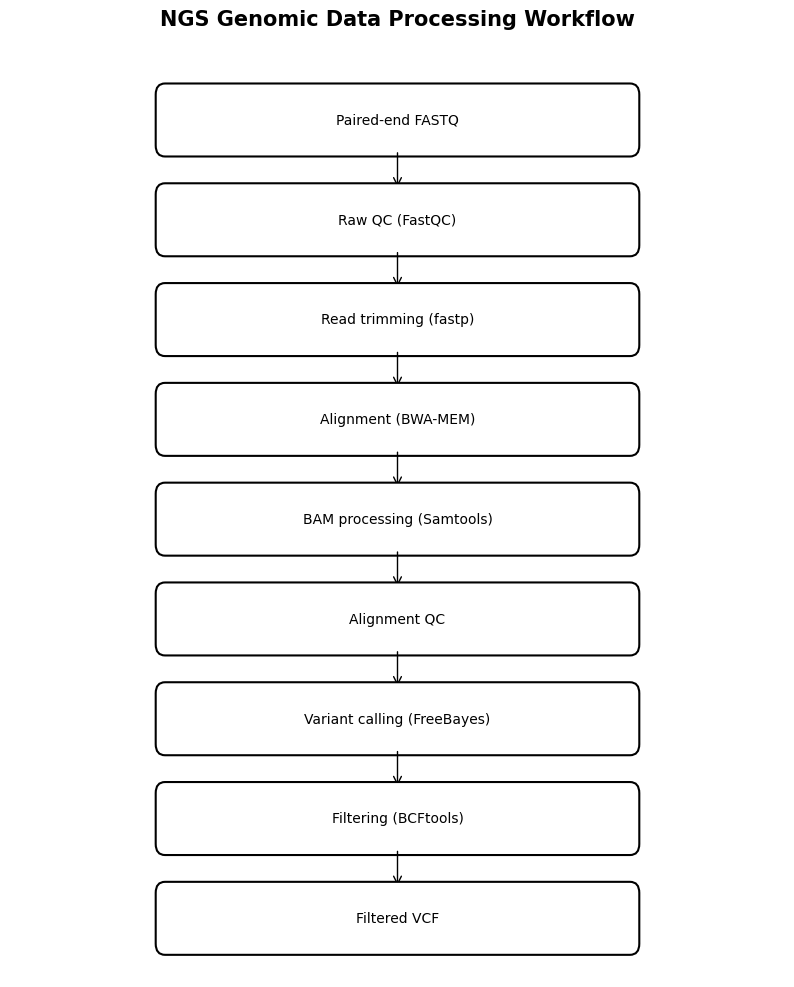

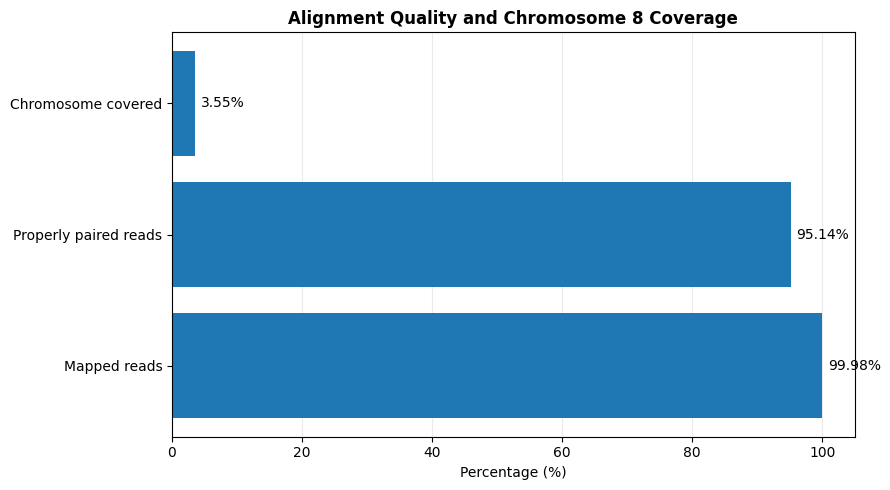

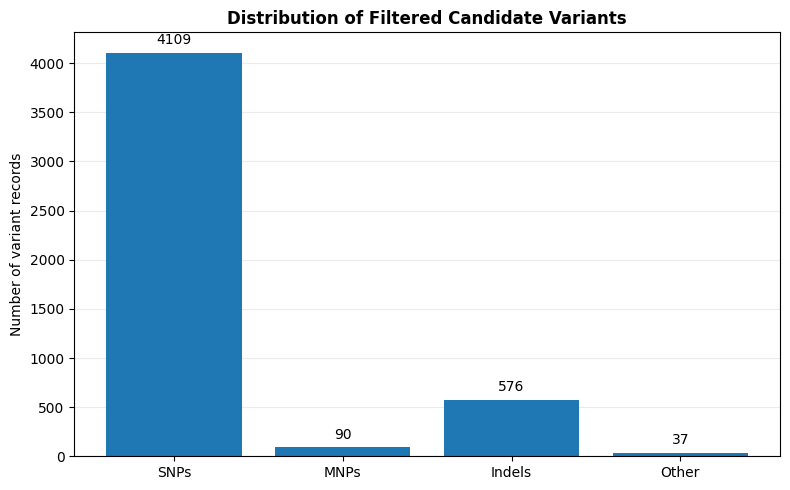

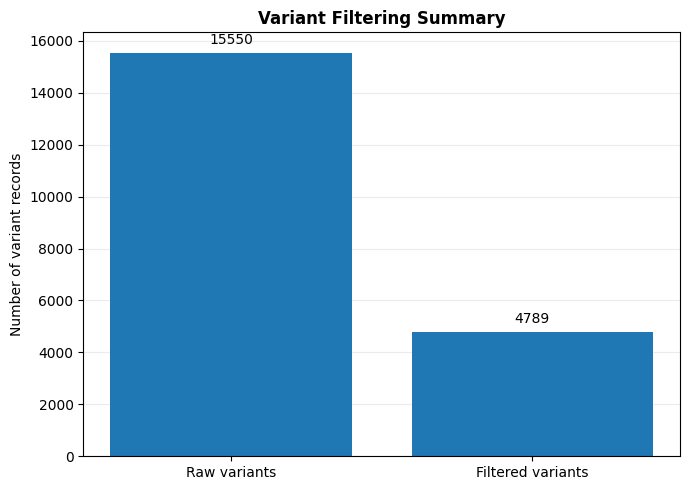

All figures saved in: /content/NGS_Pipeline/reports
['Figure1_Pipeline_Workflow.png', 'Figure4_Variant_Filtering.png', 'Figure2_Alignment_QC.png', 'Figure3_Variant_Distribution.png']


In [74]:

import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

out = "/content/NGS_Pipeline/reports"
os.makedirs(out, exist_ok=True)

# FIGURE 1: Pipeline workflow
steps = [
    "Paired-end FASTQ",
    "Raw QC (FastQC)",
    "Read trimming (fastp)",
    "Alignment (BWA-MEM)",
    "BAM processing (Samtools)",
    "Alignment QC",
    "Variant calling (FreeBayes)",
    "Filtering (BCFtools)",
    "Filtered VCF"
]

fig, ax = plt.subplots(figsize=(10, 12))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

for i, step in enumerate(steps):
    y = 9.35 - i * 1.08
    box = FancyBboxPatch(
        (2, y - 0.35), 6, 0.55,
        boxstyle="round,pad=0.12",
        edgecolor="black", facecolor="white",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(5, y - 0.075, step, ha="center", va="center", fontsize=10)

    if i < len(steps) - 1:
        ax.add_patch(FancyArrowPatch(
            (5, y - 0.4), (5, y - 0.83),
            arrowstyle="->", mutation_scale=14
        ))

ax.set_title("NGS Genomic Data Processing Workflow",
             fontsize=15, fontweight="bold", pad=20)
fig.savefig(f"{out}/Figure1_Pipeline_Workflow.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# FIGURE 2: Alignment quality and coverage
metrics = [
    "Mapped reads",
    "Properly paired reads",
    "Chromosome covered"
]
values = [99.98, 95.14, 3.55459]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(metrics, values)
ax.set_xlim(0, 105)
ax.set_xlabel("Percentage (%)")
ax.set_title("Alignment Quality and Chromosome 8 Coverage",
             fontweight="bold")
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(f"{out}/Figure2_Alignment_QC.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# FIGURE 3: Filtered variant distribution
categories = ["SNPs", "MNPs", "Indels", "Other"]
counts = [4109, 90, 576, 37]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(categories, counts)
ax.set_ylabel("Number of variant records")
ax.set_title("Distribution of Filtered Candidate Variants",
             fontweight="bold")
ax.bar_label(bars, padding=4, fmt="%d")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(f"{out}/Figure3_Variant_Distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)


# FIGURE 4: Raw vs filtered variants
labels = ["Raw variants", "Filtered variants"]
values = [15550, 4789]

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, values)
ax.set_ylabel("Number of variant records")
ax.set_title("Variant Filtering Summary", fontweight="bold")
ax.bar_label(bars, padding=4, fmt="%d")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig(f"{out}/Figure4_Variant_Filtering.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("All figures saved in:", out)
print(os.listdir(out))
